<p align='center'><img src='../assets/logo_team.png' width='140'></p>

<h1 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">Tarification non vie avec Python · Exercices I et II</h1>

**Objectif.** Comprendre le portefeuille habitation avant de modéliser : volumes, exposition, fréquence et coût moyen
des sinistres **Dégât des eaux (DDE)**, sinistres extrêmes, puis analyse univariée, bivariée, par âge, par département,
corrélations entre variables et adéquation des lois.

Les graphiques reprennent les types du cours (barres d'exposition + fréquence, courbes par exercice, bulles
Nbpieces × Nbpers…) avec la charte bleu nuit / or. Toutes les fonctions sont dans `src/` et sont partagées avec le
dashboard Streamlit.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import display

from src import theme as T, graphiques as GR
from src.data import *
from src.indicateurs import *
from src import modeles as M
print("Rendu :", T.configurer_notebook())
pd.options.display.float_format = "{:,.4f}".format

Rendu : plotly_mimetype+notebook_connected+png


In [2]:
bd = charger_base()                                  # base complète (1 112 095 lignes)
bda, bdt, samp = decouper(bd, seed=2016)             # np.random.seed(2016) ; np.random.choice(len(bd), 300000)
print(f"Base : {bd.shape} · apprentissage : {len(bda):,} · test : {len(bdt):,}")

Base : (1112095, 24) · apprentissage : 300,000 · test : 812,095


<h2 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">Exercice I</h2>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">1. Variables explicatives tarifaires et variables clés</h3>

In [3]:
bd.info()
print('Valeurs manquantes :', bd.drop(columns=['Age_num']).isna().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1112095 entries, 0 to 1112094
Data columns (total 24 columns):
 #   Column      Non-Null Count    Dtype   
---  ------      --------------    -----   
 0   Exercice    1112095 non-null  int64   
 1   Couverture  1112095 non-null  category
 2   Nbpieces    1112095 non-null  category
 3   Nbpers      1112095 non-null  category
 4   Qualite     1112095 non-null  category
 5   Kassu       1112095 non-null  category
 6   Age         1112095 non-null  str     
 7   Usage       1112095 non-null  category
 8   Local       1112095 non-null  category
 9   Direct      1112095 non-null  category
 10  DMG         1112095 non-null  category
 11  Zonier_DDE  1112095 non-null  category
 12  Ante_DDE    1112095 non-null  category
 13  Zonier_Vol  1112095 non-null  category
 14  Ante_Vol    1112095 non-null  category
 15  Sini_DDE    1112095 non-null  float64 
 16  Sini_Vol    1112095 non-null  float64 
 17  Cout_DDE    1112095 non-null  float64 
 18  Cout_Vol    1

| Rôle | Variables |
|---|---|
| **Variables à expliquer (fréquence)** | `Sini_DDE`, `Sini_Vol` : nombre de sinistres de la ligne |
| **Variables à expliquer (coût)** | `Cout_DDE`, `Cout_Vol` : charge de la ligne (coût moyen = charge / nombre) |
| **Exposition** | `Expo` : durée de couverture en années, utilisée en *offset* du GLM de fréquence |
| **Contrôle** | `Exercice` (2006 à 2013) : sert à vérifier la stabilité, pas à tarifer |
| **Variables tarifaires** | `Couverture`, `Nbpieces`, `Nbpers`, `Qualite`, `Kassu`, `Age2`, `Usage`, `Local`, `Direct`, `DMG`, `Zonier_DDE`, `Ante_DDE` (et `Zonier_Vol`, `Ante_Vol` pour le Vol) |
| **Variables brutes à transformer** | `Age` (85 valeurs, résumé par `Age2`) et `Dep` (96 départements, résumé par les zoniers) |

In [4]:
display(bd[['Sini_DDE','Cout_DDE','Sini_Vol','Cout_Vol','Expo']].describe().T)

,count,mean,std,min,25%,50%,75%,max
Sini_DDE,"1,112,095.0000",0.0186,0.1428,0.0000,0.0000,0.0000,0.0000,6.0000
Cout_DDE,"1,112,095.0000",24.4559,357.9233,0.0000,0.0000,0.0000,0.0000,"90,049.2885"
Sini_Vol,"1,112,095.0000",0.0107,0.1076,0.0000,0.0000,0.0000,0.0000,4.0000
Cout_Vol,"1,112,095.0000",29.4574,443.1342,0.0000,0.0000,0.0000,0.0000,"97,963.9300"
Expo,"1,112,095.0000",1.0543,0.9863,0.0849,0.6425,1.0000,1.0000,48.0975


<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">2. Indicateurs du portefeuille (a à e)</h3>

In [5]:
tab = table_par_exercice(bd, "DDE")
display(tab.style.format({"Nb_contrats": "{:,.0f}", "Exposition": "{:,.1f}", "Nb_sinistres": "{:,.0f}",
                          "Charge": "{:,.0f} €", "Fréquence": "{:.3%}", "Coût moyen": "{:,.1f} €",
                          "Prime pure": "{:,.2f} €", "Part expo": "{:.1%}"}))
print(f"Lignes avec plus d'un an d'exposition : {(bd['Expo'] > 1).mean():.1%}")

,Exercice,Exposition,Nb_sinistres,Charge,Nb_contrats,Fréquence,Coût moyen,Prime pure,Part expo
0,2006,"116,354.1","2,089","2,809,863 €","114,529",1.795%,"1,345.1 €",24.15 €,9.9%
1,2007,"135,147.8","2,392","3,063,857 €","129,332",1.770%,"1,280.9 €",22.67 €,11.5%
2,2008,"143,153.3","2,535","3,139,635 €","136,916",1.771%,"1,238.5 €",21.93 €,12.2%
3,2009,"148,040.1","2,642","3,654,678 €","140,256",1.785%,"1,383.3 €",24.69 €,12.6%
4,2010,"152,351.1","2,596","3,511,526 €","143,720",1.704%,"1,352.7 €",23.05 €,13.0%
5,2011,"156,833.2","2,829","4,018,922 €","146,899",1.804%,"1,420.6 €",25.63 €,13.4%
6,2012,"159,019.7","2,783","3,502,744 €","149,381",1.750%,"1,258.6 €",22.03 €,13.6%
7,2013,"161,579.4","2,792","3,496,029 €","151,062",1.728%,"1,252.2 €",21.64 €,13.8%
8,Total,"1,172,478.8","20,658","27,197,254 €","1,112,095",1.762%,"1,316.5 €",23.20 €,100.0%


Lignes avec plus d'un an d'exposition : 16.4%


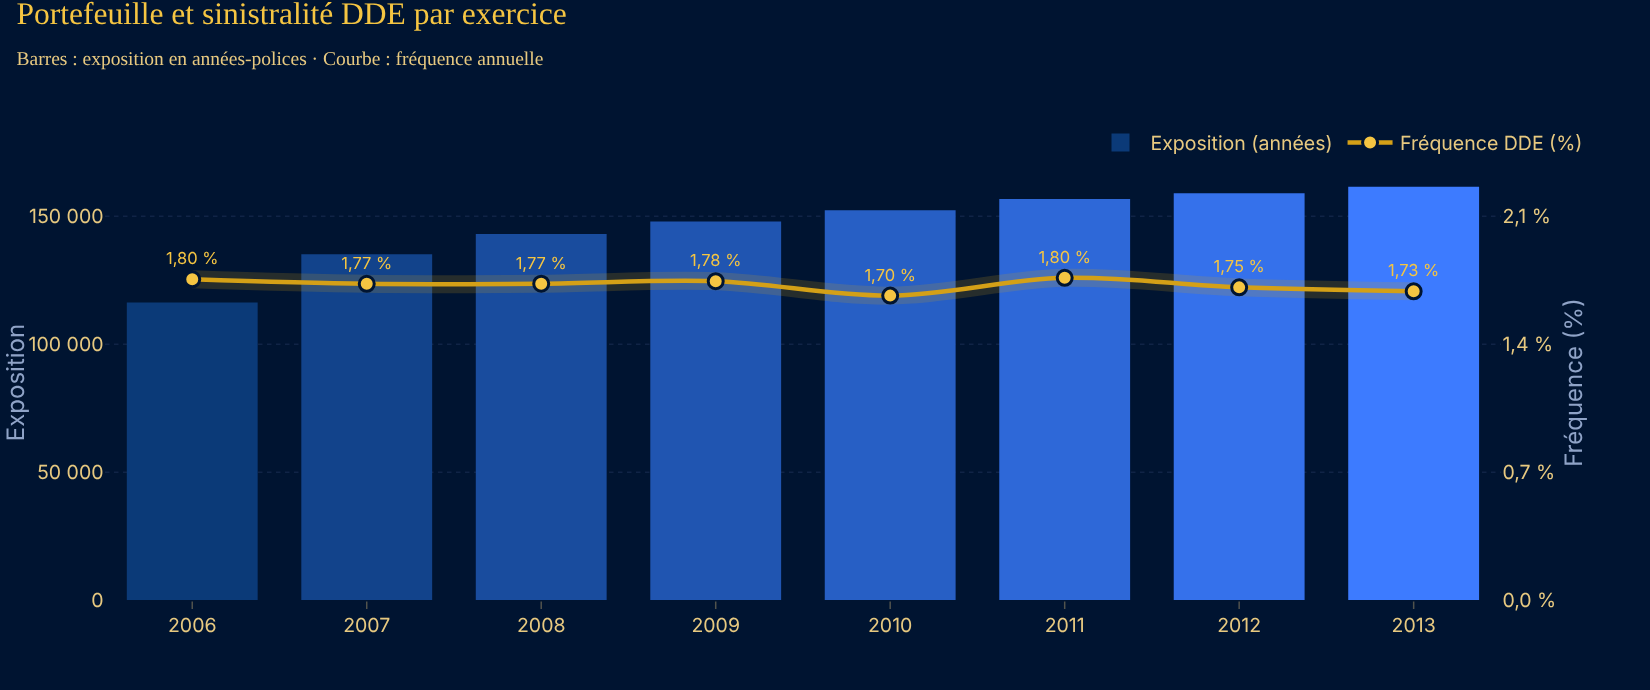

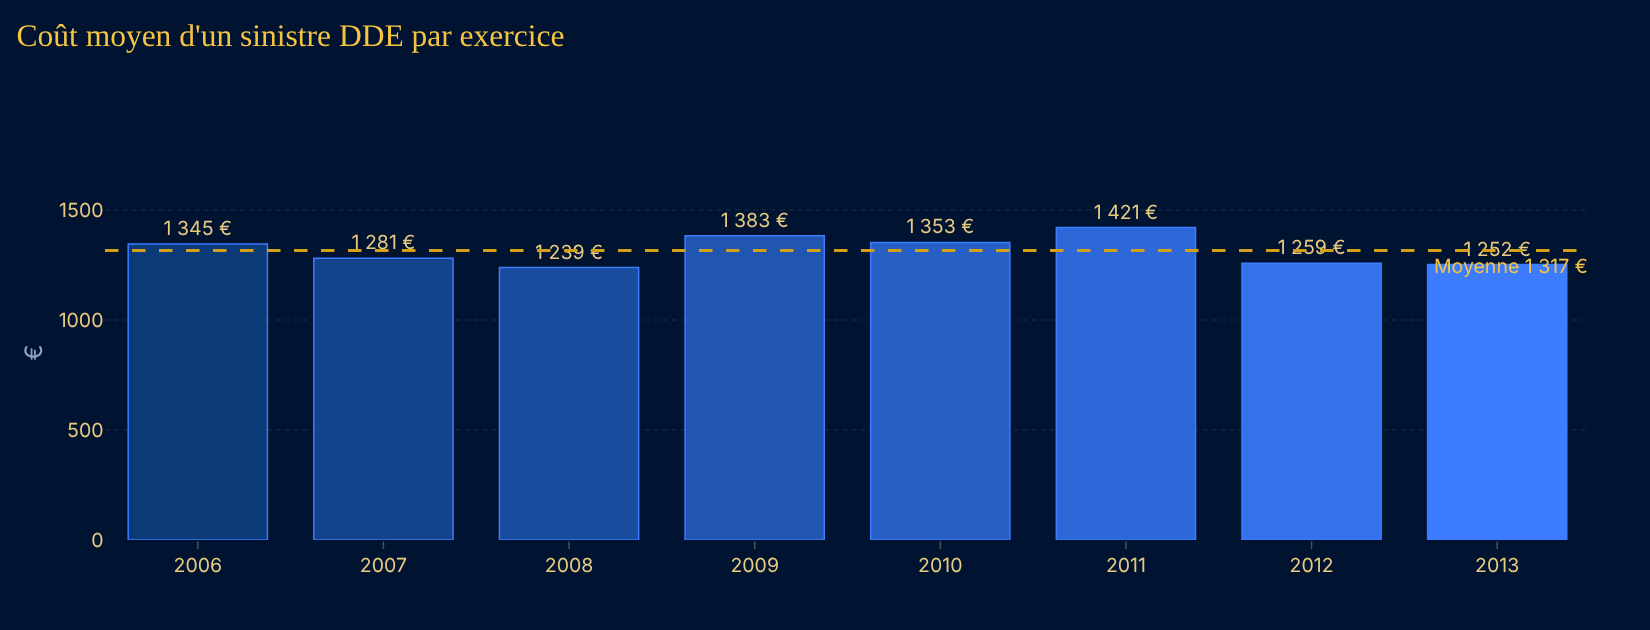

In [6]:
GR.kpi_exercice(tab, 'DDE').show()
GR.cout_moyen_exercice(tab, 'DDE').show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> **a.** 1 112 095 contrats souscrits (lignes) ; le nombre de **contrats annuels** est l'exposition, soit
≈ 1 172 479 années-polices (16 % des lignes couvrent plus d'un an). **b.** L'exposition croît de 2006 à 2013.
**c.** 20 658 sinistres DDE pour 27,2 M€. **d.** Fréquence globale ≈ **1,76 %**, stable par exercice.
**e.** Coût moyen ≈ **1 317 €**, sans tendance marquée : pas de dérive temporelle à corriger.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">3. Sinistralité extrême en DDE</h3>

count    19,569
mean      1,324
std       2,183
min           0
50%         858
90%       2,434
99%       8,847
99.9%    24,271
max      90,049
Name: Coût unitaire, dtype: str
Borne Q3 + 1,5 IQR = 3,200 € · 1,238 sinistres au-delà
Part de la charge des 1 % les plus graves : 12.1%


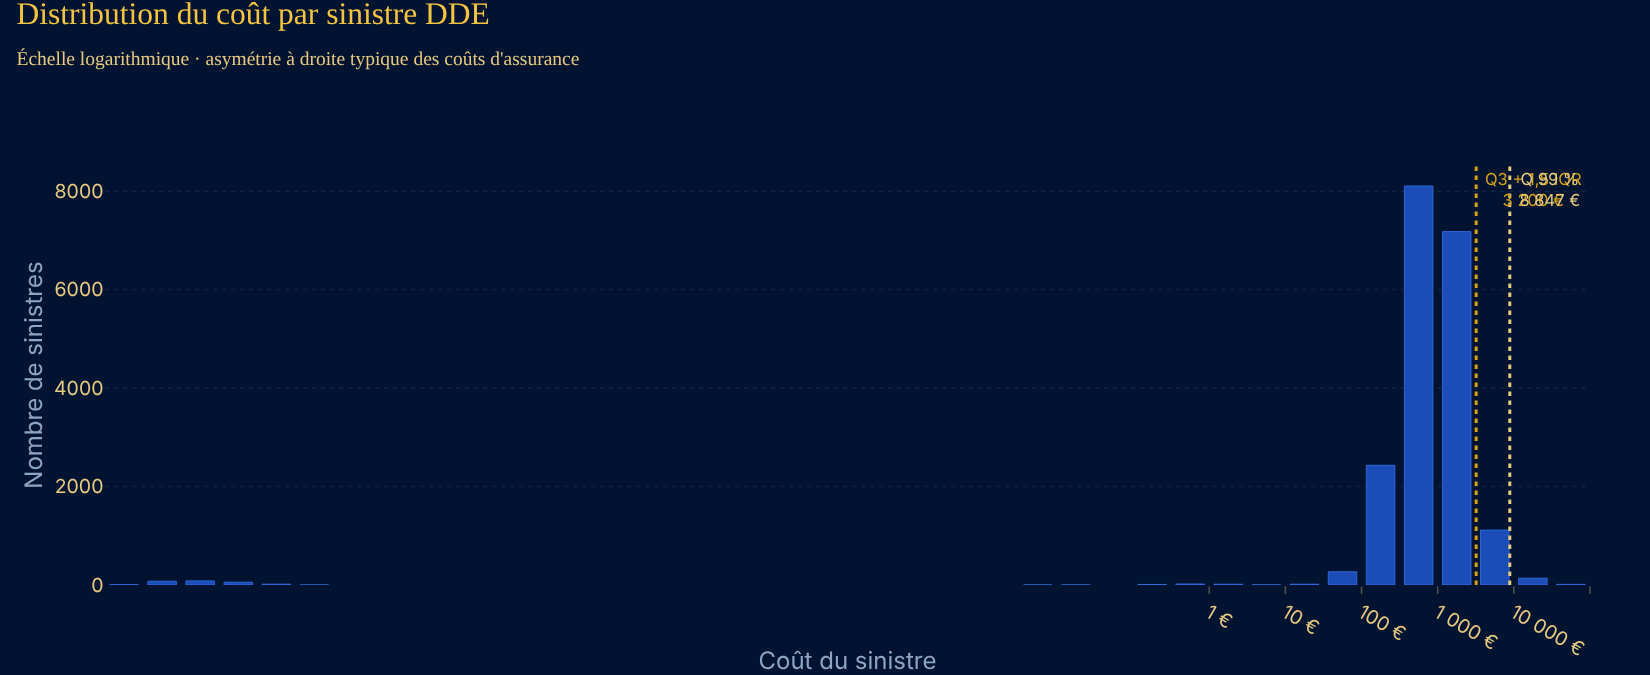

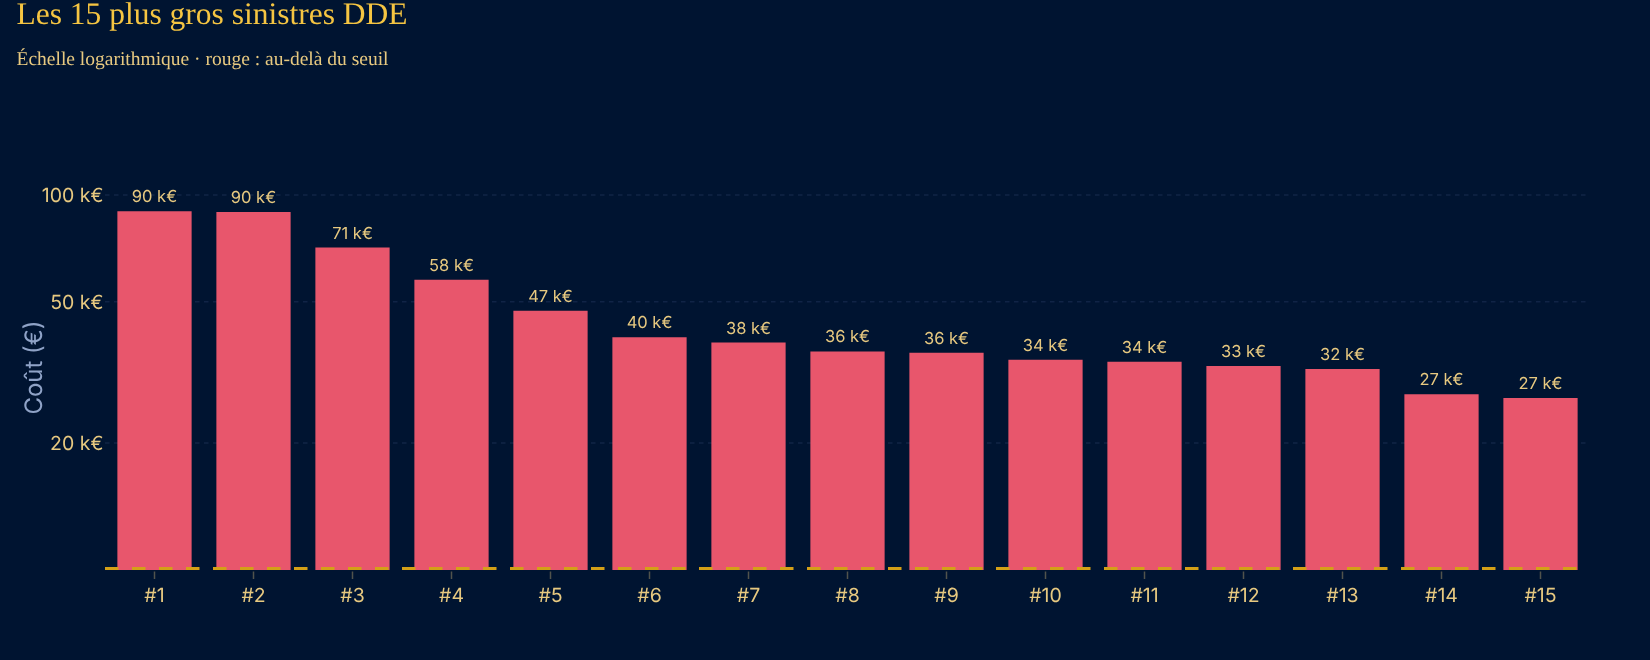

In [7]:
cu = couts_unitaires(bd, "DDE")
print(cu.describe(percentiles=[.5, .9, .99, .999]).apply("{:,.0f}".format))
q1, q3 = cu.quantile([.25, .75]); borne = q3 + 1.5 * (q3 - q1)
print(f"Borne Q3 + 1,5 IQR = {borne:,.0f} € · {(cu > borne).sum():,} sinistres au-delà")
print(f"Part de la charge des 1 % les plus graves : {cu[cu > cu.quantile(.99)].sum() / cu.sum():.1%}")
GR.histogramme_couts(cu, {"Q3 + 1,5 IQR": borne, "Q 99 %": cu.quantile(.99)}).show()
GR.top_sinistres(cu, 15, cu.quantile(.99), "DDE").show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> Distribution très asymétrique à droite : la médiane est bien inférieure à la moyenne, quelques sinistres dépassent
50 000 € (maximum ≈ 90 000 €). Ces valeurs restent plausibles pour un dégât des eaux important : on les conserve
en DDE. La règle Q3 + 1,5 IQR signale beaucoup de points mais n'est pas adaptée aux lois à queue épaisse ; le vrai
retraitement des graves est traité à l'exercice VII.</div>

<h2 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">Exercice II · Étude de la sinistralité DDE</h2>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">1. Stabilité temporelle de la Couverture</h3>

Couverture,C1,C2,C3
Exercice,,,
2006,36.44%,63.26%,0.30%
2007,36.76%,62.93%,0.31%
2008,36.64%,63.02%,0.33%
2009,36.92%,62.76%,0.31%
2010,36.69%,62.99%,0.33%
2011,36.75%,62.97%,0.29%
2012,36.66%,63.01%,0.33%
2013,36.74%,62.93%,0.32%


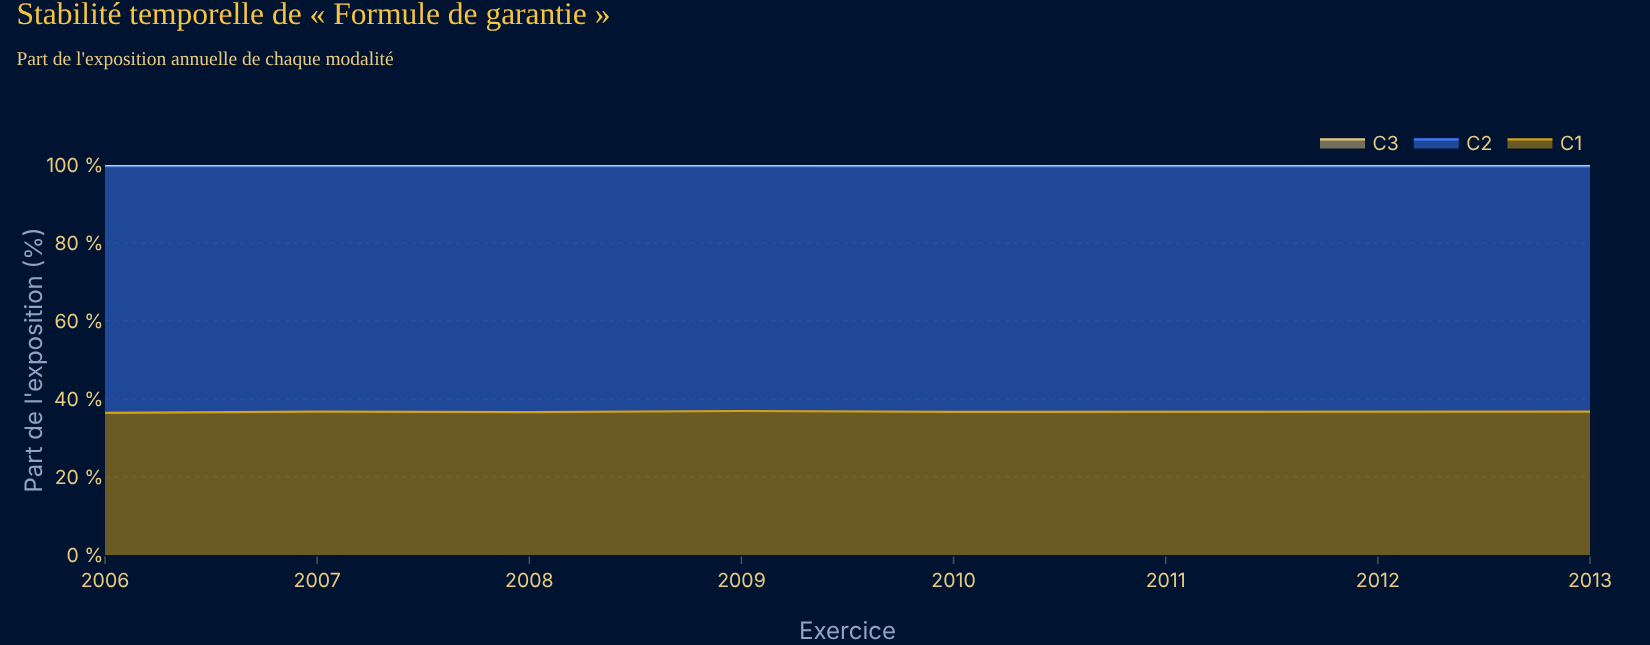

In [8]:
t = part_expo_annuelle(bd, "Couverture")
display(t.pivot(index="Exercice", columns="Couverture", values="Part expo").style.format("{:.2%}"))
GR.stabilite_modalites(t, "Couverture").show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> Les parts d'exposition de C1 (≈ 37 %), C2 (≈ 63 %) et C3 (≈ 0,3 %) bougent de moins d'un demi-point par an : le portefeuille ne se déforme pas, les années sont comparables.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">2. Analyse univariée de la Couverture</h3>

,Couverture,Exposition,Nb_sinistres,Charge,Nb_contrats,Fréquence,Coût moyen,Prime pure,Part expo
0,C1,"430,390",6891.000000,"9,069,978",400212,1.60%,"1,316 €",21.07 €,36.7%
1,C2,"738,390",13652.000000,"17,916,539",707348,1.85%,"1,312 €",24.26 €,63.0%
2,C3,"3,699",115.000000,"210,737",4535,3.11%,"1,832 €",56.97 €,0.3%


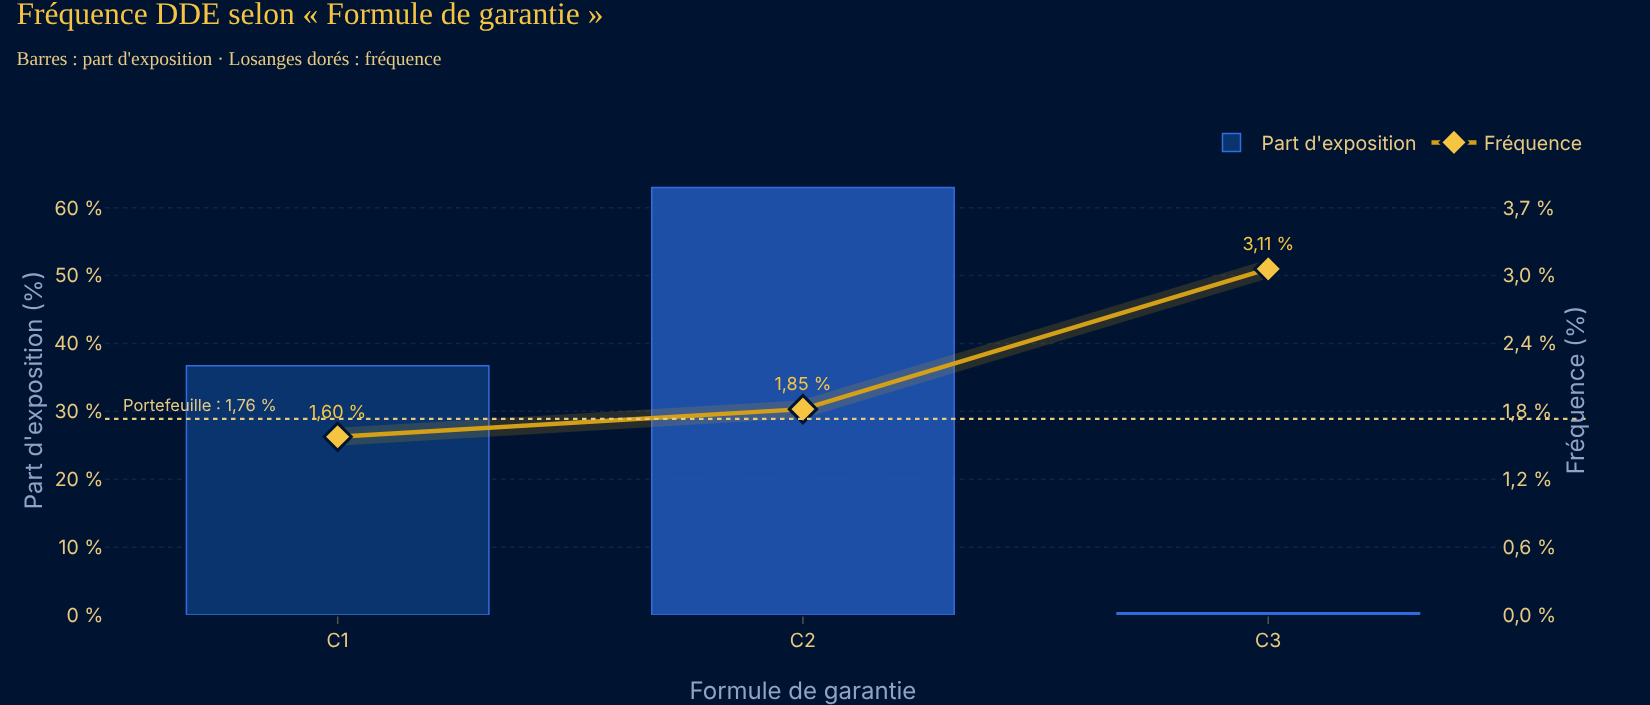

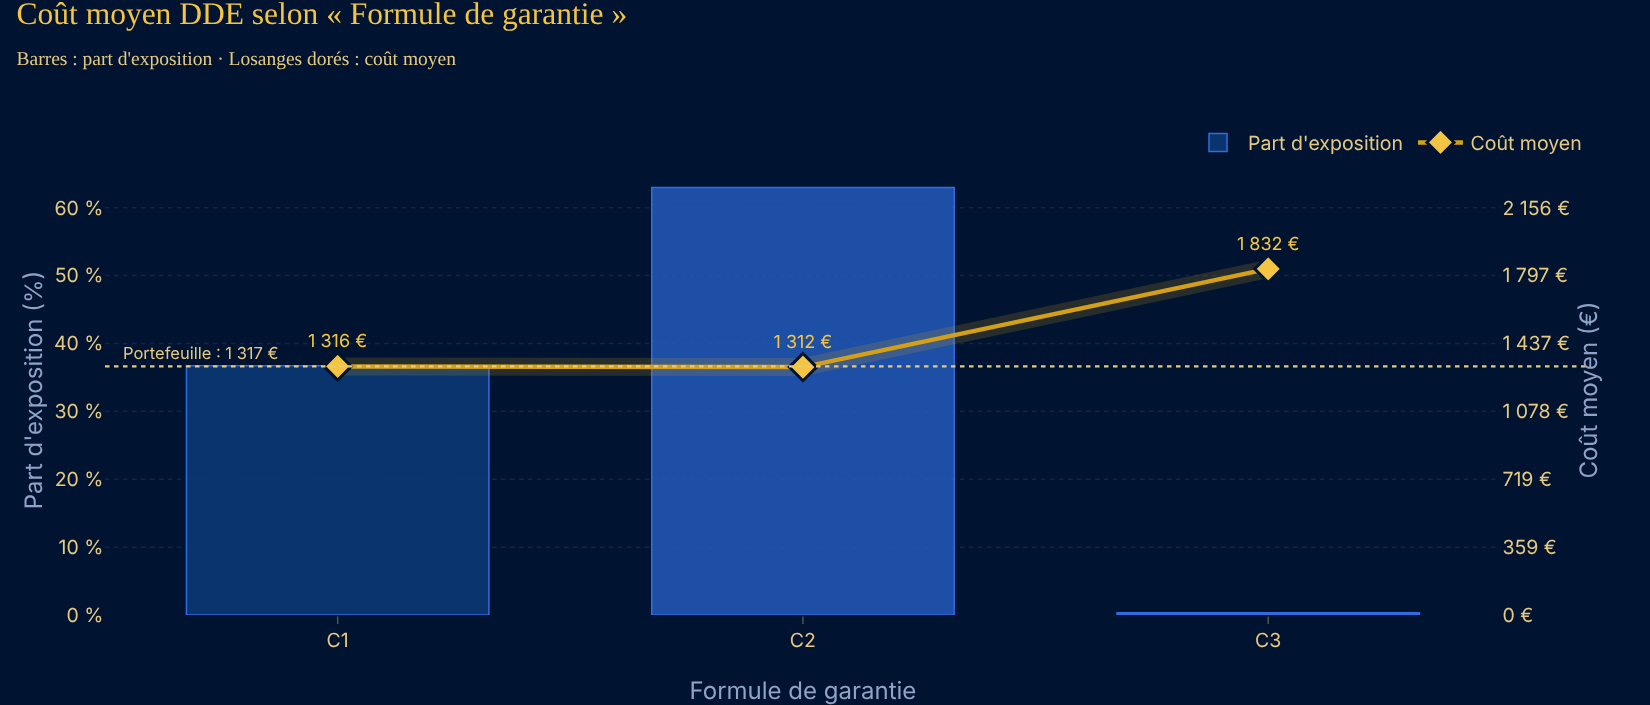

In [9]:
t = table_indicateurs(bd, "Couverture")
display(t.style.format({"Exposition": "{:,.0f}", "Charge": "{:,.0f}", "Fréquence": "{:.2%}", "Coût moyen": "{:,.0f} €",
                        "Prime pure": "{:,.2f} €", "Part expo": "{:.1%}"}))
GR.univarie(t, "Couverture", "DDE", "Fréquence").show()
GR.univarie(t, "Couverture", "DDE", "Coût moyen").show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> C2 a une fréquence plus élevée que C1 (1,85 % contre 1,60 %) pour un coût moyen proche. C3 est la plus risquée (fréquence ≈ 3,1 %, CM ≈ 1 830 €) mais repose sur environ 140 sinistres : estimation fragile.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">3. Stabilité annuelle des fréquences et coûts moyens</h3>

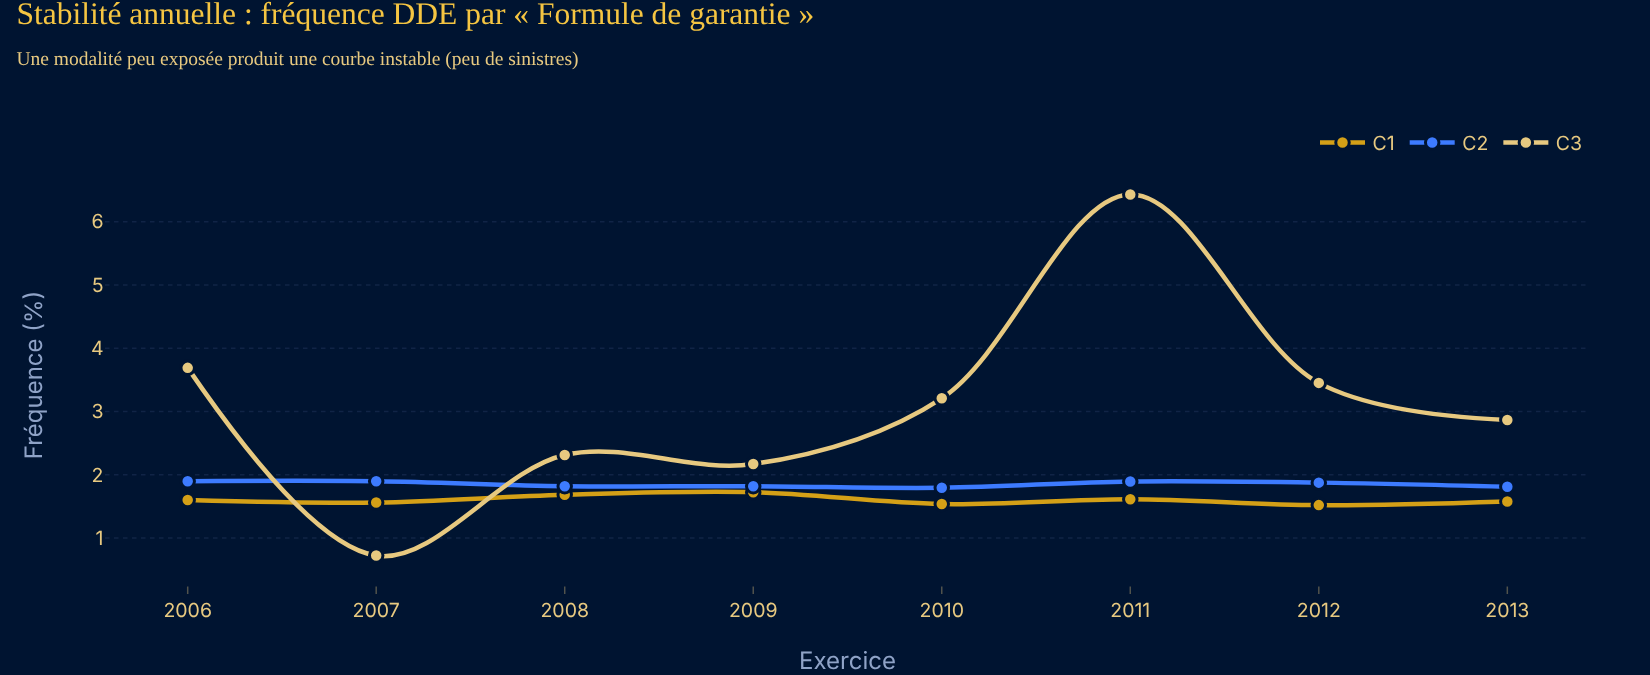

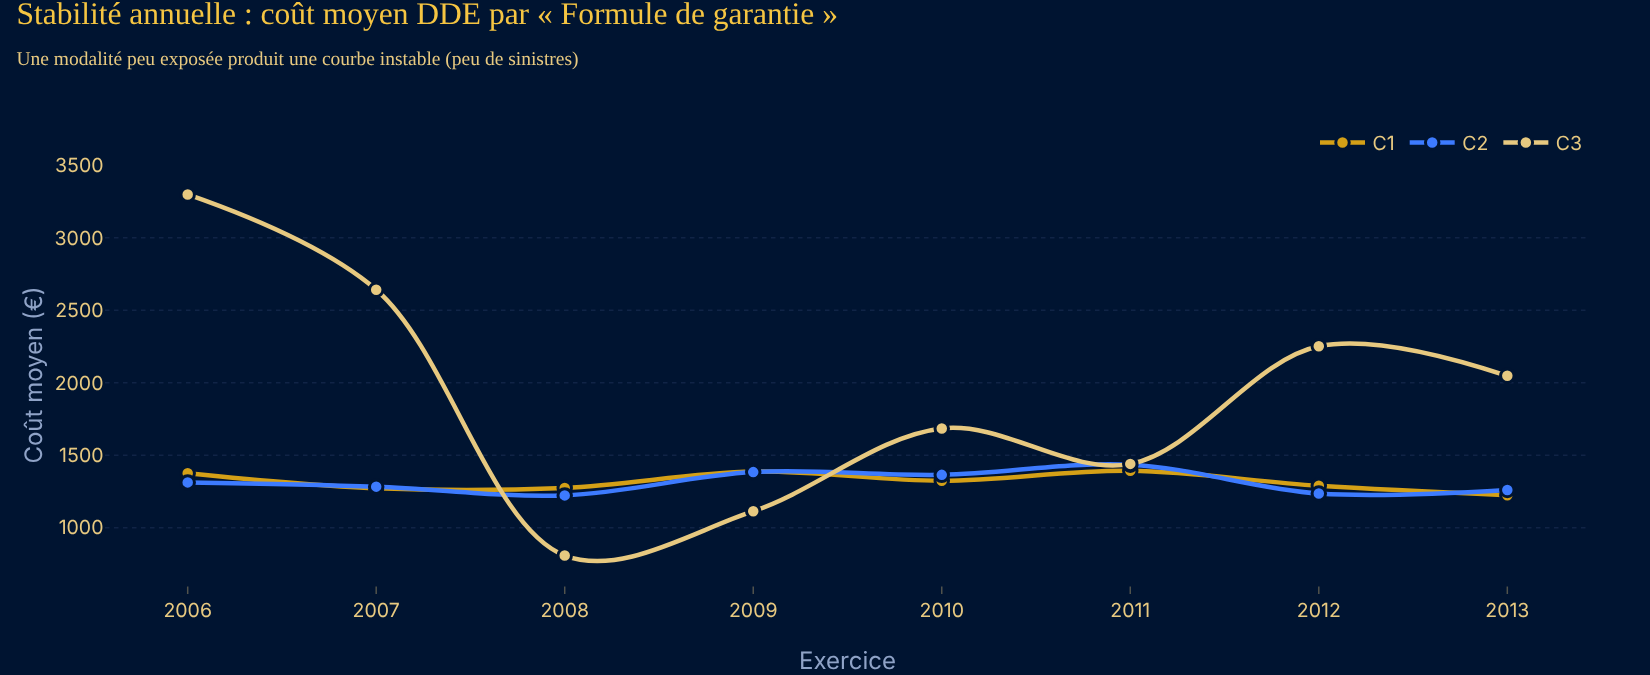

In [10]:
t = table_indicateurs(bd, ["Exercice", "Couverture"])
GR.evolution_par_modalite(t, "Couverture", "Fréquence").show()
GR.evolution_par_modalite(t, "Couverture", "Coût moyen").show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> C1 et C2 sont stables (fréquence entre 1,5 et 1,9 %, CM entre 1 200 et 1 450 €). Les courbes de C3 oscillent fortement car elles reposent sur 3 à 29 sinistres par an : c'est du bruit, pas une tendance.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">4. Analyse bivariée Nbpieces × Nbpers</h3>

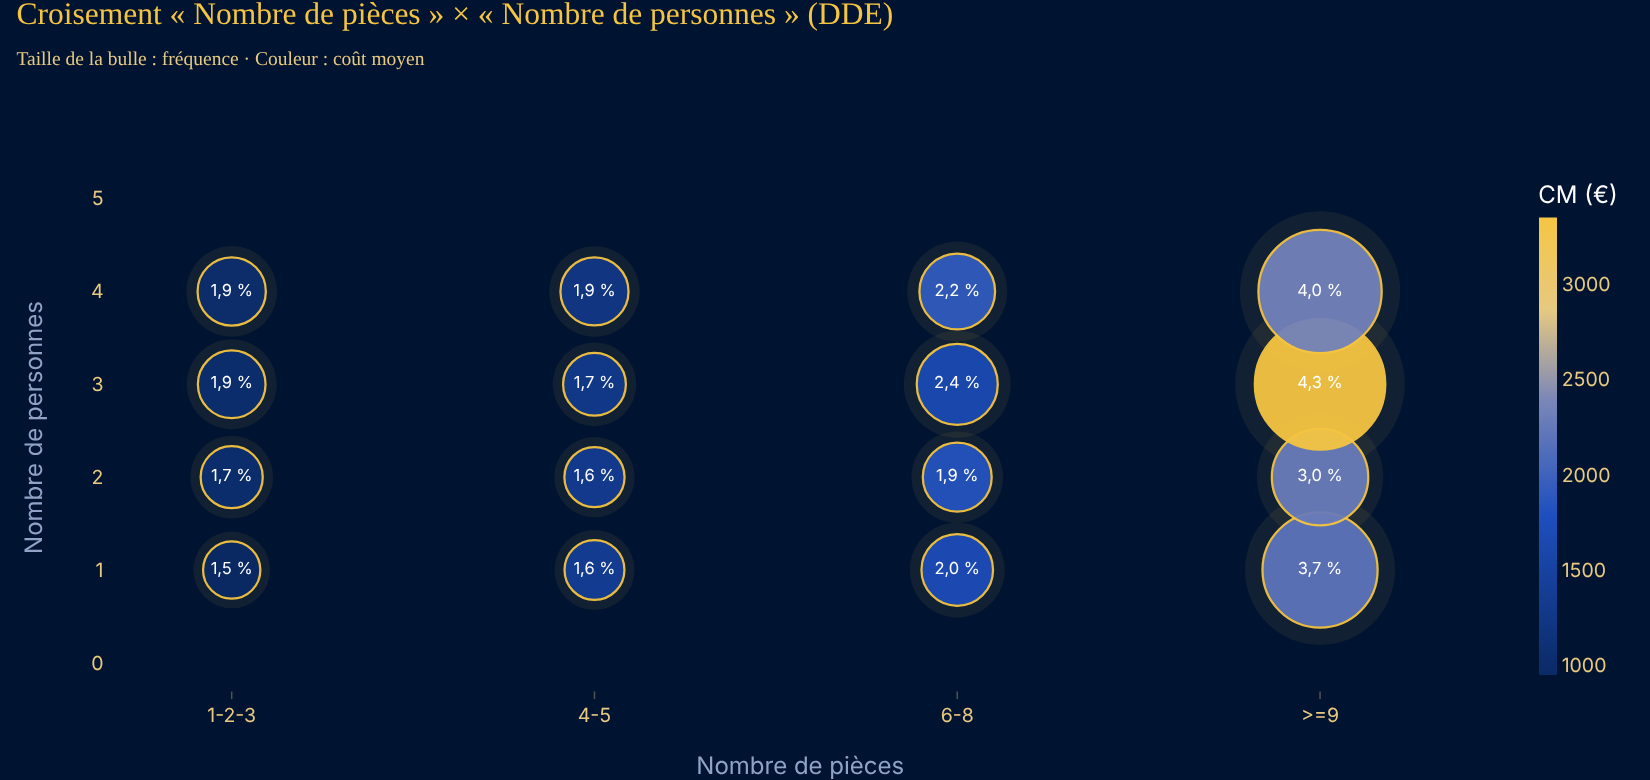

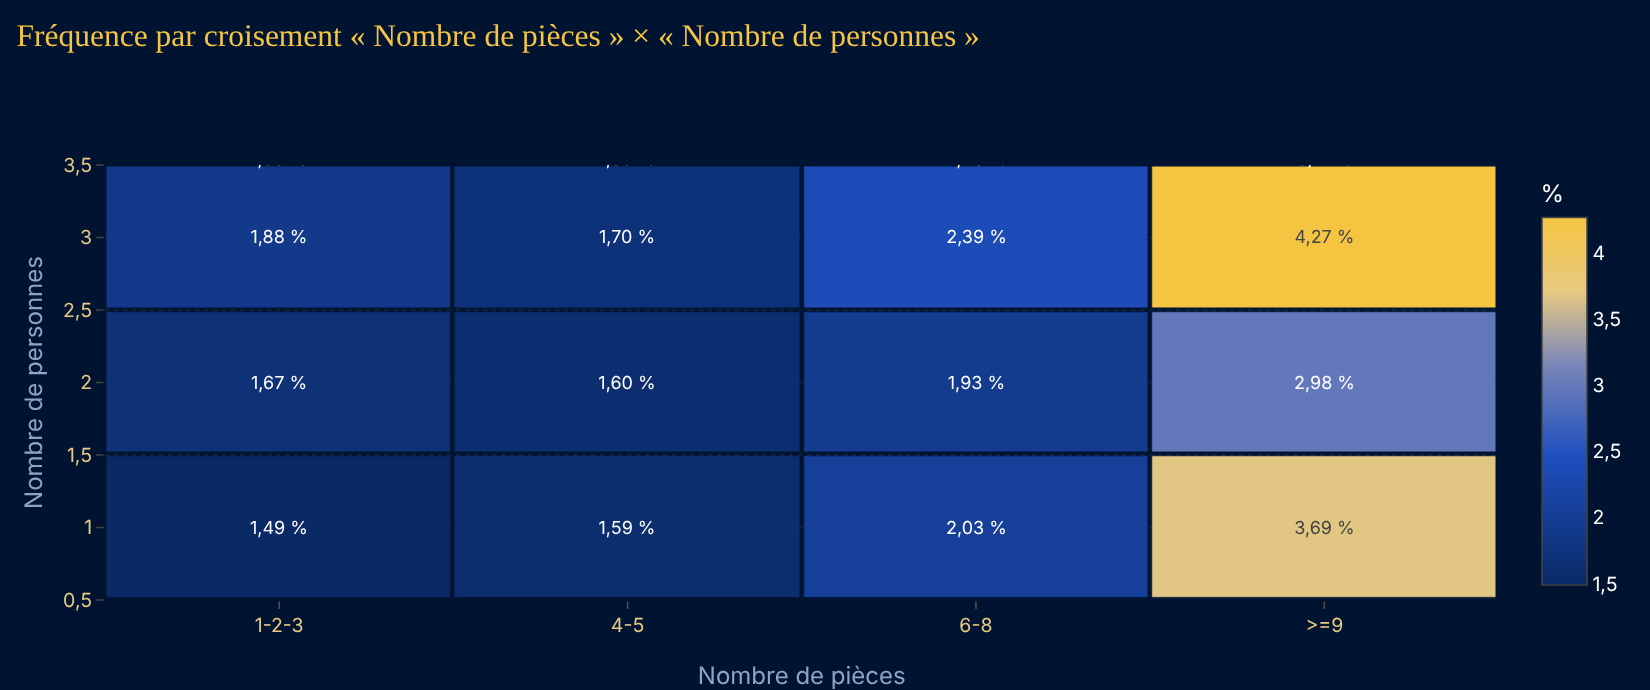

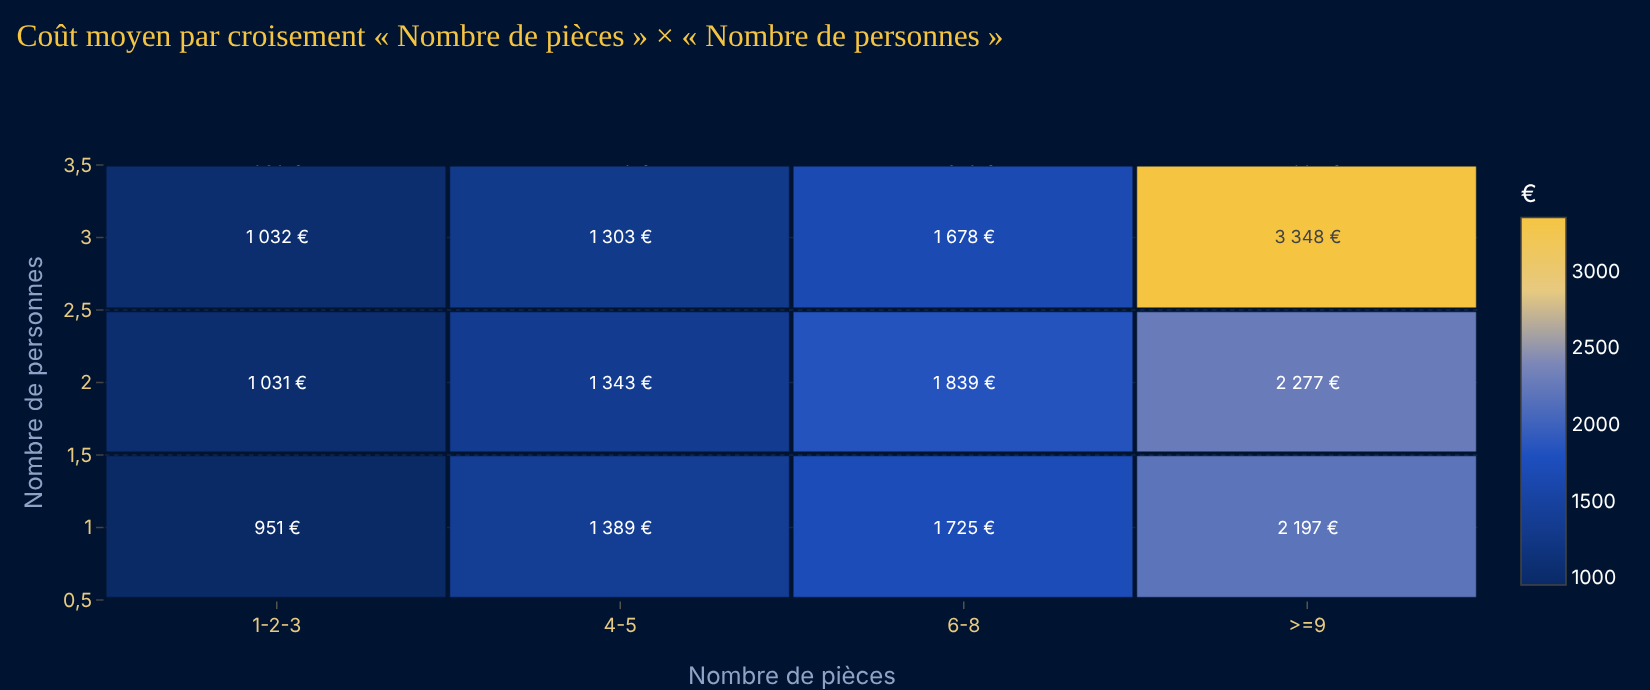

In [11]:
t = table_indicateurs(bd, ["Nbpieces", "Nbpers"])
GR.bulles_croisement(t, "Nbpieces", "Nbpers").show()
GR.heatmap_croisement(t, "Nbpieces", "Nbpers", "Fréquence").show()
GR.heatmap_croisement(t, "Nbpieces", "Nbpers", "Coût moyen").show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> Le **nombre de pièces** est le facteur dominant : la fréquence passe d'environ 1,6 % (1-3 pièces) à plus de 3 % (9 pièces et plus) et le coût moyen augmente avec la surface. À taille donnée, le nombre de personnes joue peu. Les effets semblent à peu près additifs (en log), ce que l'on vérifiera avec l'interaction en GLM.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">5. Sinistralité par âge</h3>

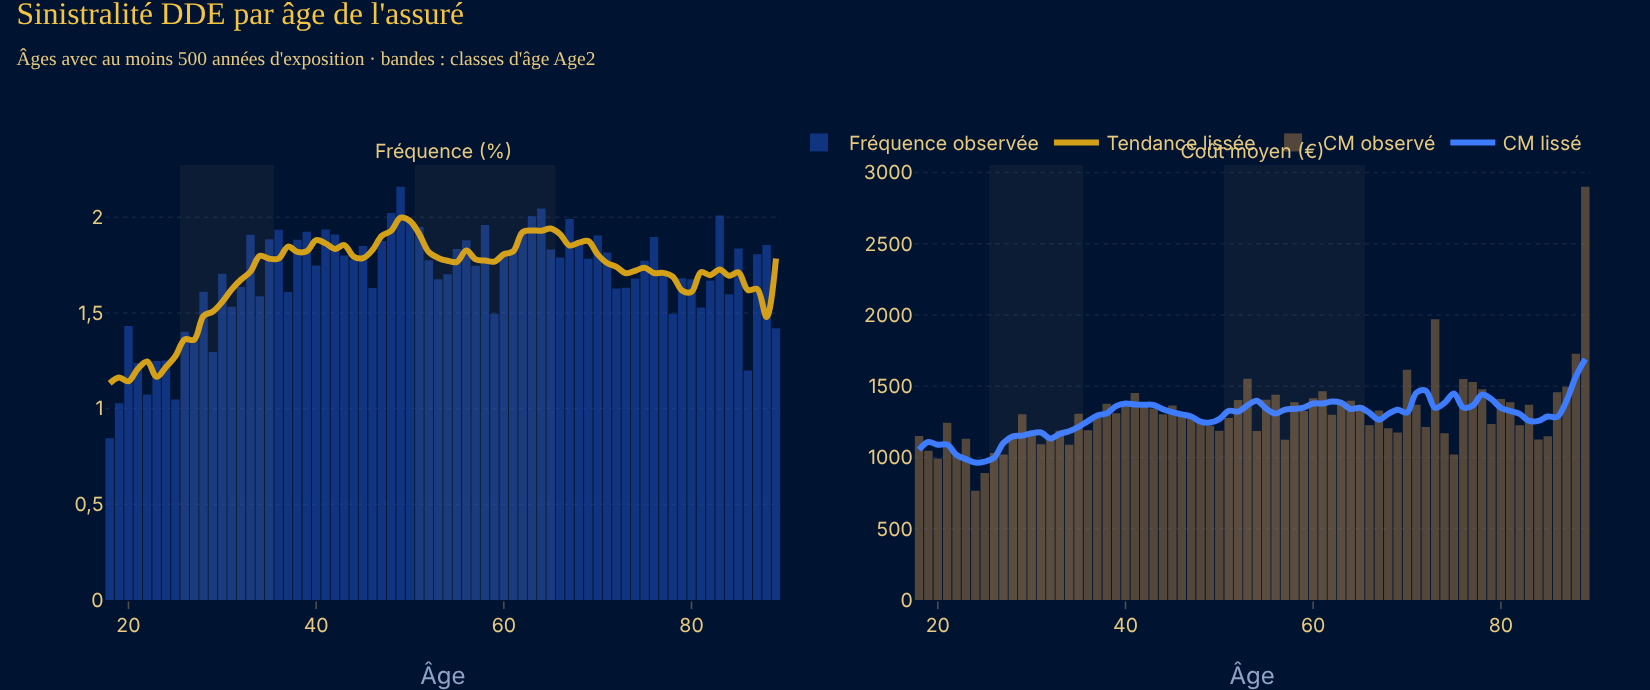

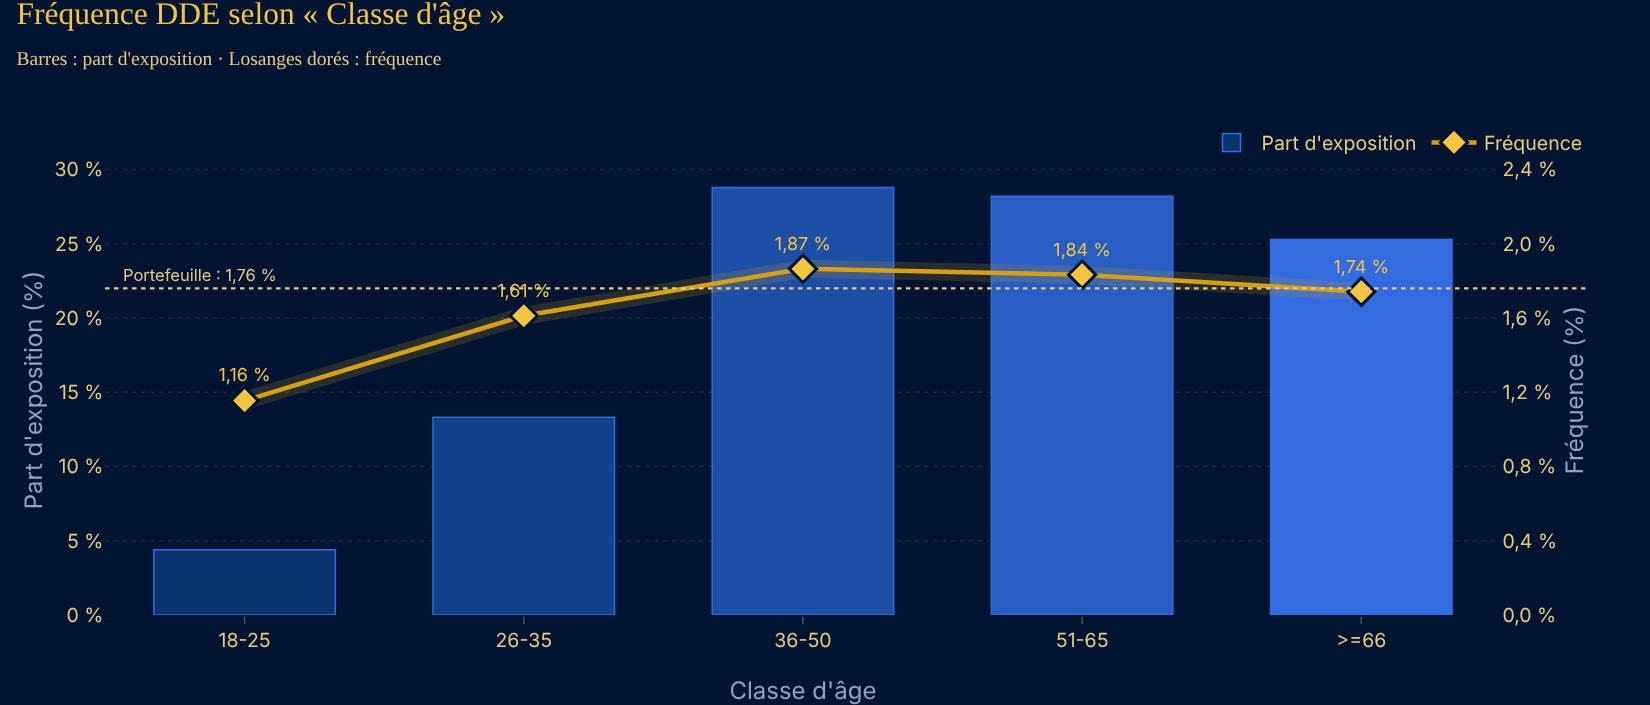

In [12]:
t = table_indicateurs(bd, "Age_num")
GR.sinistralite_age(t).show()
GR.univarie(table_indicateurs(bd, "Age2"), "Age2", "DDE", "Fréquence").show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> La fréquence augmente jusqu'à 35-50 ans puis se stabilise, le coût moyen croît avec l'âge. **Contraintes d'une
variable quantitative au tarif** : le GLM impose une forme fonctionnelle (linéaire en log) qui ne colle pas à une
relation non monotone, les âges extrêmes sont peu exposés (estimations bruitées), la prime ne doit pas sauter à
chaque anniversaire et le tarif doit rester explicable. Solutions : classes d'âge (Age2), lissage polynomial ou
splines, puis regroupement.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">6. Sinistralité par département</h3>

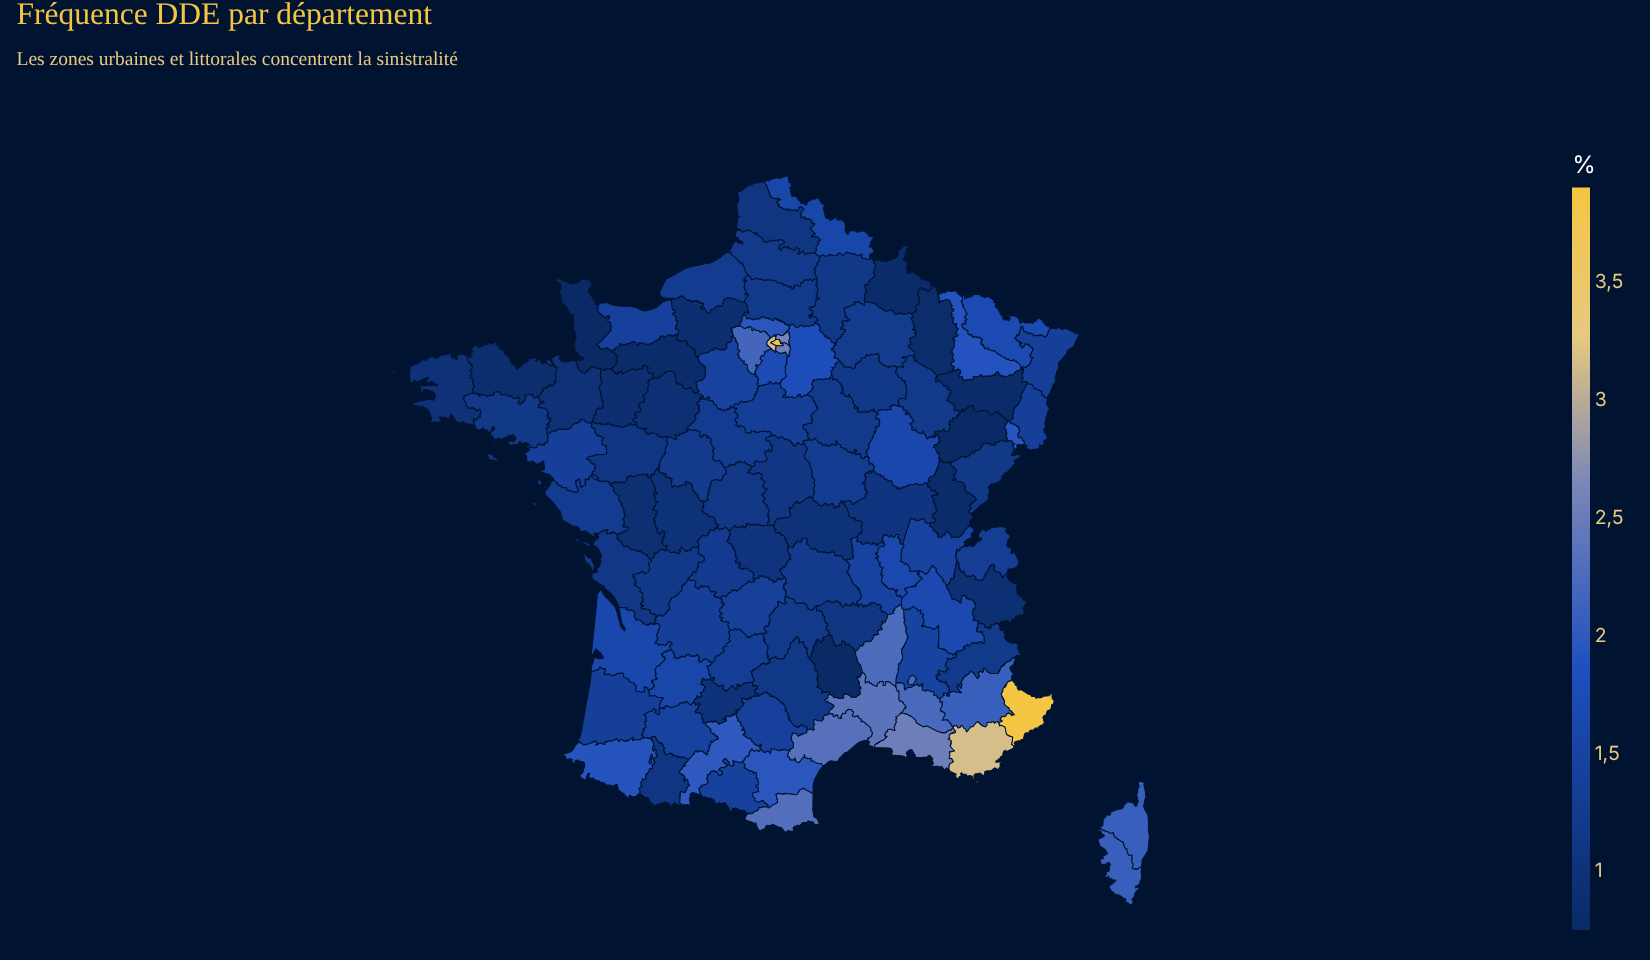

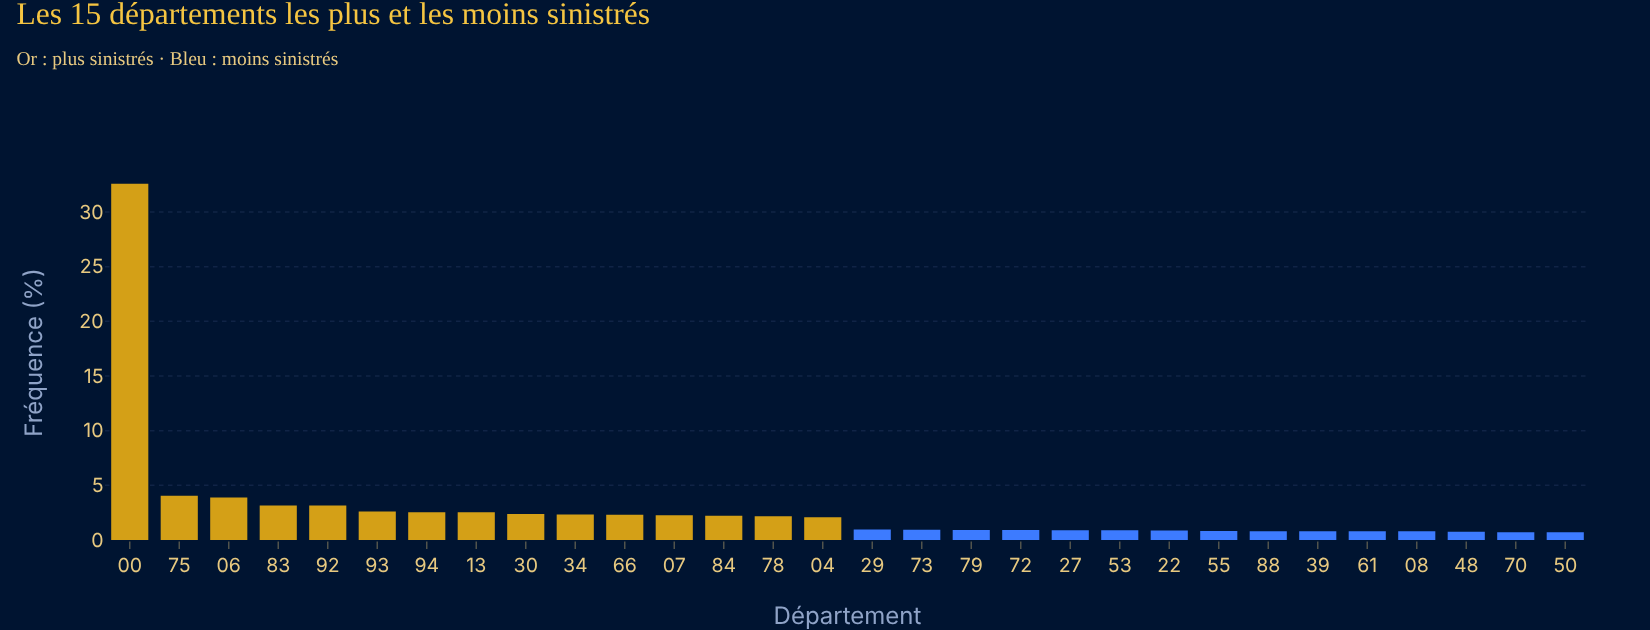

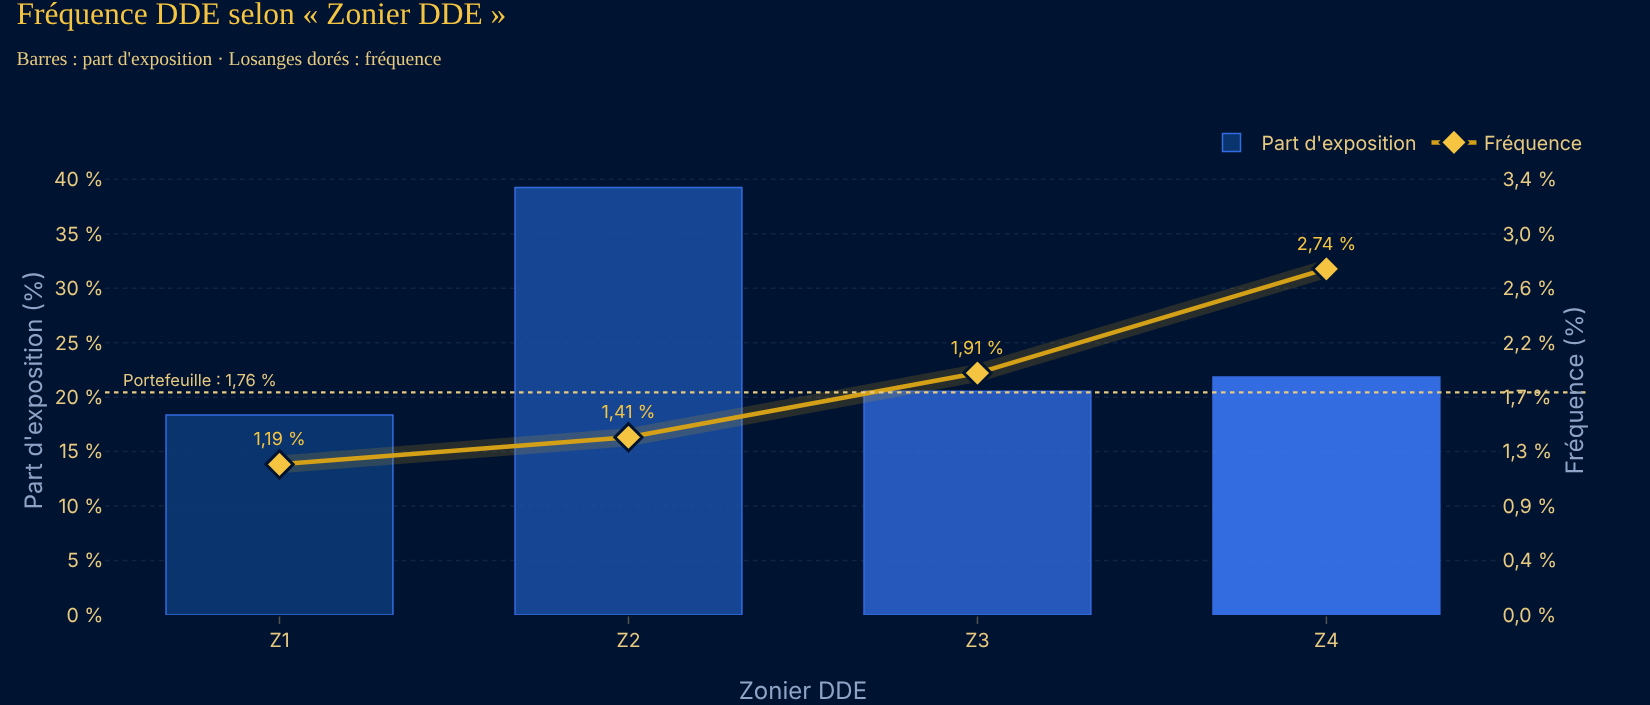

In [13]:
import json
geo = json.loads((Path.cwd().parent / "assets" / "departements.geojson").read_text(encoding="utf-8"))
t = table_indicateurs(bd, "Dep")
GR.carte_departements(t, geo, "Fréquence").show()
GR.classement_departements(t, "Fréquence").show()
GR.univarie(table_indicateurs(bd, "Zonier_DDE"), "Zonier_DDE", "DDE", "Fréquence").show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> La fréquence varie de moins de 1 % à près de 4 % selon le département (Paris, Hauts-de-Seine, Alpes-Maritimes, Var en
tête). Avec 96 modalités souvent peu exposées, le département ne peut pas entrer tel quel dans le GLM. **On intègre
la géographie par un zonier** : on estime l'effet géographique résiduel (après les autres variables), on le lisse
(crédibilité, voisinage) et on regroupe les départements en 4-5 zones homogènes. Le zonier DDE de la base est bien
croissant de Z1 à Z4. Le code « 00 » (département inconnu) mérite une vérification de qualité de données.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">7. Corrélations entre variables tarifaires (V de Cramer)</h3>

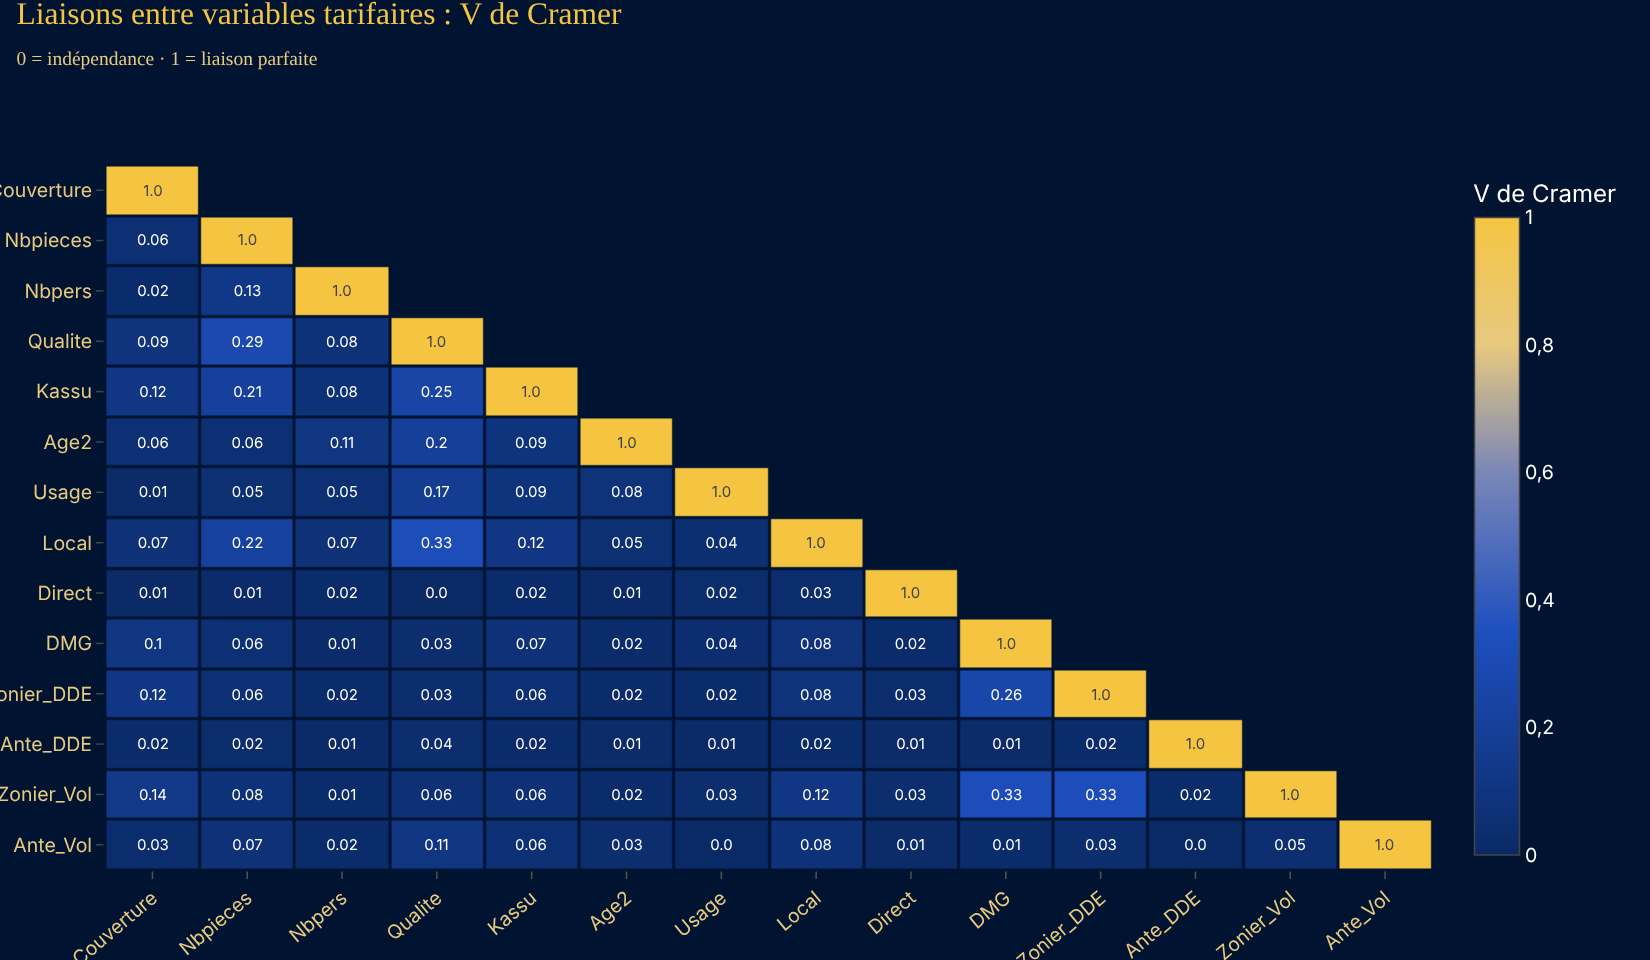

,,V de Cramer
Zonier_DDE,Zonier_Vol,0.3343
DMG,Zonier_Vol,0.3312
Qualite,Local,0.3277
Nbpieces,Qualite,0.2921
DMG,Zonier_DDE,0.2639
Qualite,Kassu,0.2515


In [14]:
m = matrice_cramer(bd, VAR_TARIF_DDE + ["Zonier_Vol", "Ante_Vol"])
GR.heatmap_cramer(m).show()
paires = m.where(np.triu(np.ones(m.shape, bool), 1)).stack().sort_values(ascending=False)
display(paires.head(6).to_frame("V de Cramer"))

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> Toutes les liaisons restent modérées (V de Cramer ≤ 0,34). Les plus fortes relient les deux zoniers (Zonier_DDE × Zonier_Vol, logique : ils sont construits sur la même géographie), DMG aux zoniers, puis Qualite × Local (les propriétaires habitent surtout des maisons) et Nbpieces × Qualite. Aucune redondance n'empêche d'utiliser ces variables ensemble dans un GLM, mais l'effet propre de Qualite et de Local devra être lu « toutes choses égales par ailleurs ».</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">8. Adéquation des lois</h3>

λ = 0.0176 · variance/moyenne = 1.098 · khi-deux (0, 1, ≥2) : stat = 1398.9, p = 0.000


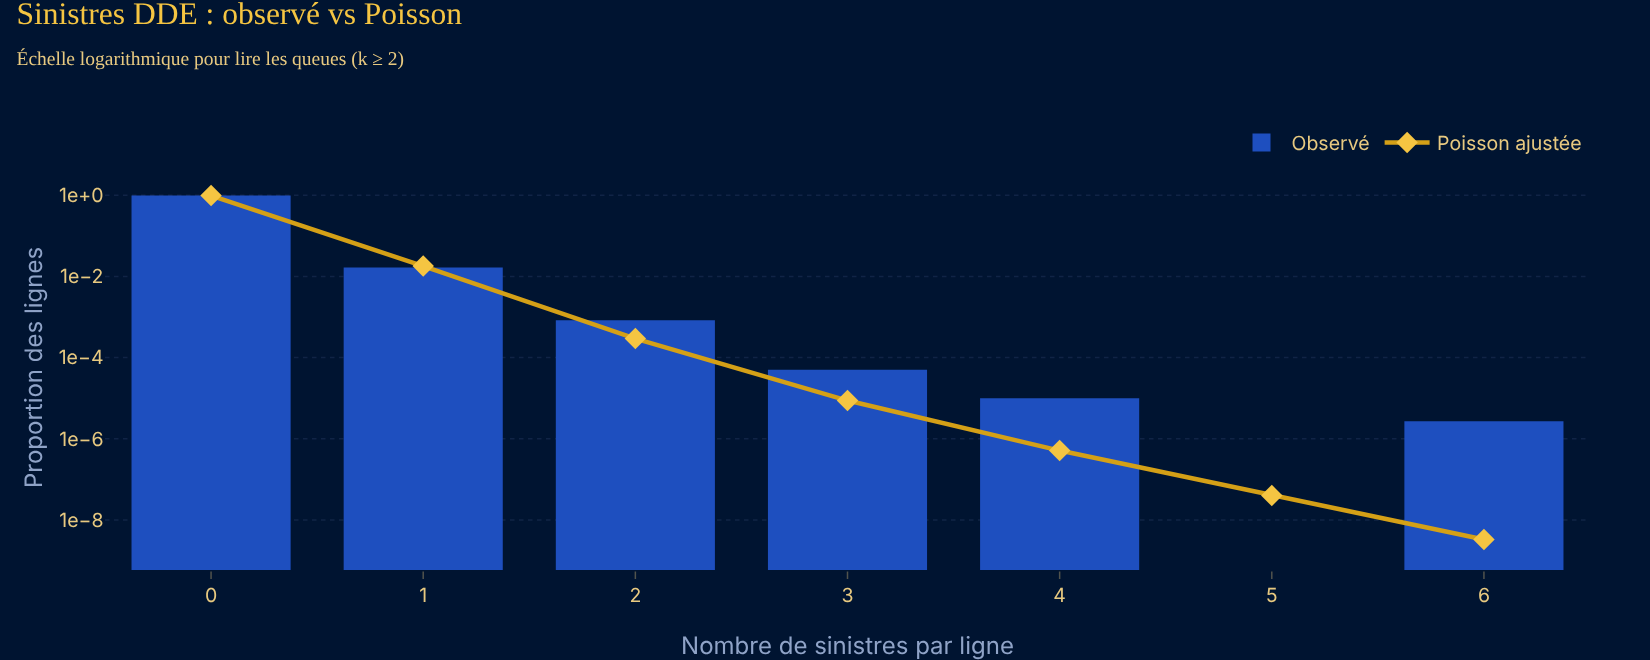

In [15]:
from scipy import stats
N = bd["Sini_DDE"].astype(int).to_numpy(); e = bd["Expo"].to_numpy()
lam = N.sum() / e.sum(); k = np.arange(0, 7)
p_obs = pd.Series(N).value_counts(normalize=True).reindex(k, fill_value=0).to_numpy()
p_th = np.array([stats.poisson.pmf(j, lam * e).mean() for j in k])
n = len(N); obs = p_obs[:3] * n; th = np.r_[p_th[:2], 1 - p_th[:2].sum()] * n
obs = np.r_[obs[:2], n - obs[:2].sum()]
chi = stats.chisquare(obs, th, ddof=1)
print(f"λ = {lam:.4f} · variance/moyenne = {N.var() / N.mean():.3f} · khi-deux (0, 1, ≥2) : stat = {chi.statistic:.1f}, p = {chi.pvalue:.3f}")
GR.adequation_poisson(k, p_obs, p_th).show()

Gamma        KS D = 0.3113 · p-value = 0.00e+00
Log-normale  KS D = 0.0383 · p-value = 4.56e-25


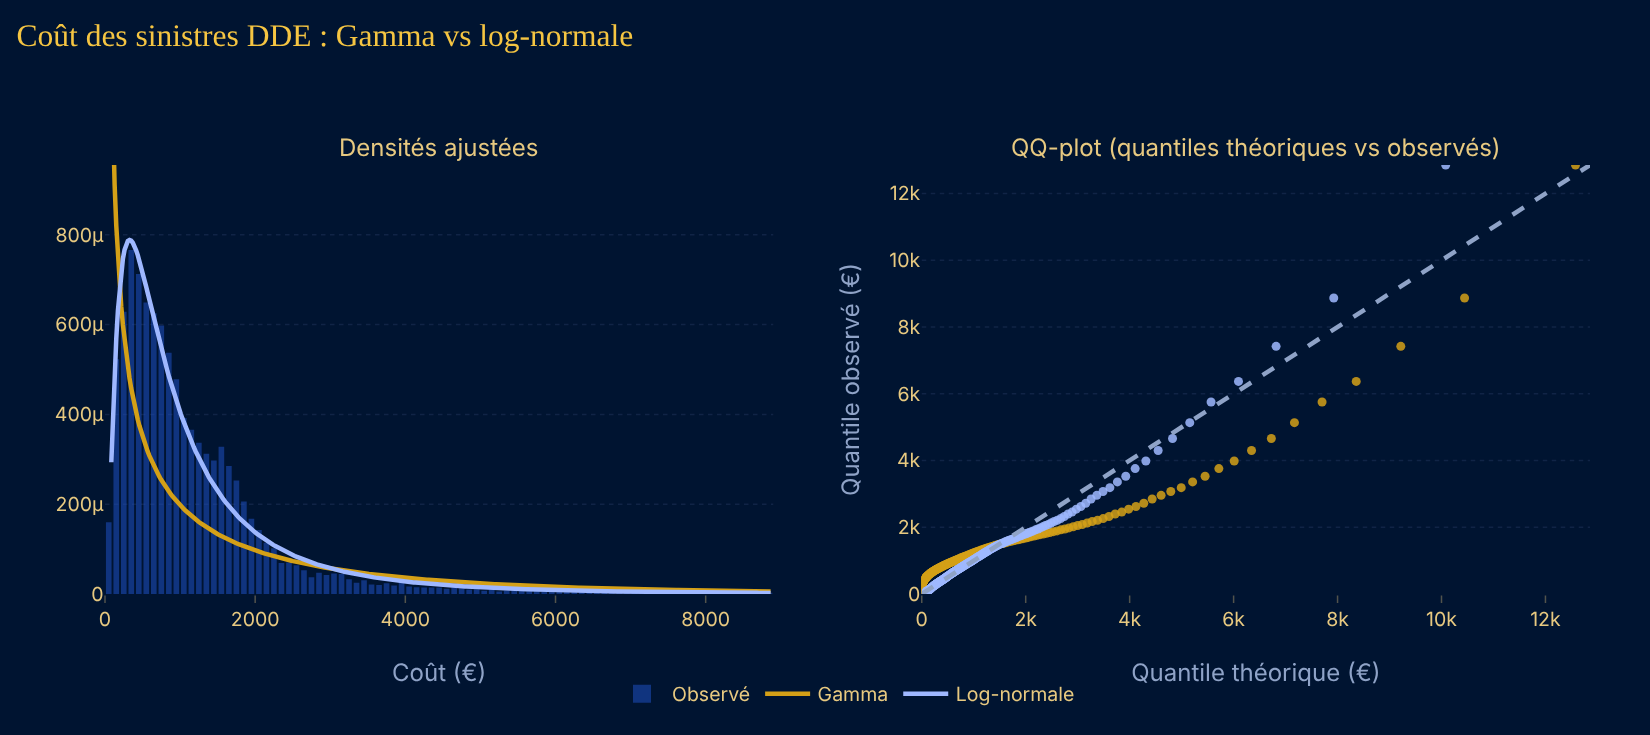

In [16]:
cu1 = cu[cu >= 1].to_numpy()             # on retire les sinistres classés sans suite (< 1 €)
mo, va = cu1.mean(), cu1.var()
gam = stats.gamma(mo ** 2 / va, scale=va / mo)          # Gamma par la méthode des moments (comme le cours)
s, _, sc = stats.lognorm.fit(cu1, floc=0); ln = stats.lognorm(s, scale=sc)
for nom, loi in [("Gamma", gam), ("Log-normale", ln)]:
    ks = stats.kstest(cu1, loi.cdf)
    print(f"{nom:12s} KS D = {ks.statistic:.4f} · p-value = {ks.pvalue:.2e}")
GR.adequation_couts(cu1, {"Gamma": gam, "Log-normale": ln}).show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> **Fréquence** : la loi de Poisson pondérée par l'exposition reproduit bien la forme des effectifs, avec une légère
**surdispersion** (variance / moyenne ≈ 1,10). Le test du khi-deux la rejette, ce qui est attendu sur 1,1 million de
lignes et avec une fréquence unique pour tous : l'hétérogénéité entre assurés crée la surdispersion, et c'est
précisément ce que les variables tarifaires du GLM vont capter. Le GLM de Poisson reste le modèle de référence
(une binomiale négative serait l'alternative si la surdispersion persistait après segmentation). **Coût** : les deux lois sont rejetées par le test
(sur 20 000 observations, le moindre écart devient significatif) ; la log-normale suit mieux la queue (D plus petit).
On retient néanmoins le **GLM Gamma** pour le coût moyen : il modélise l'espérance avec une variance proportionnelle
au carré de la moyenne, hypothèse suffisante pour estimer une prime, et ses relativités sont directement
multiplicatives avec le lien log.</div>